<a href="https://colab.research.google.com/github/nigamshivanshu/Trust_Safety_Risk_Operations_Analytics/blob/develop/Trust_Safety_Risk_Operations_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trust & Safety Risk Operations Analytics

## Project objective
Evaluate how an email platform can prioritize suspicious messages for investigation while minimizing false positives against legitimate email.

## Data source
Apache SpamAssassin Public Mail Corpus

## Initial scope
- Collect and preserve the original dataset archives.
- Document dataset provenance and limitations.
- Validate the downloaded files before beginning analysis.
- Use interpretable machine learning and risk-based operational analysis.

## Important limitation
The corpus is historical and does not represent current Gmail traffic or establish real-world phishing detection performance.

In [ ]:

from pathlib import Path
from urllib.request import urlopen
import tarfile
import hashlib
import json
import time

# Project directory
PROJECT_DIR = Path("/content/trust_safety_risk_analytics")
RAW_DIR = PROJECT_DIR / "data" / "raw"
EXTRACT_DIR = RAW_DIR / "extracted"

RAW_DIR.mkdir(parents=True, exist_ok=True)
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

BASE_URL = "https://spamassassin.apache.org/old/publiccorpus/"

ARCHIVES = [
    "20030228_easy_ham.tar.bz2",
    "20030228_hard_ham.tar.bz2",
    "20030228_spam.tar.bz2",
    "20030228_easy_ham_2.tar.bz2",
    "20030228_spam_2.tar.bz2",
]

results = []

for filename in ARCHIVES:
    archive_path = RAW_DIR / filename
    url = BASE_URL + filename

    try:
        # Download only if not already present
        if not archive_path.exists():
            print(f"Downloading: {filename}")

            with urlopen(url, timeout=60) as response:
                archive_path.write_bytes(response.read())

        # Verify archive integrity by reading its contents
        with tarfile.open(archive_path, mode="r:bz2") as tar:
            members = [
                member for member in tar.getmembers()
                if member.isfile()
            ]

            # Extract safely: reject absolute paths and traversal paths
            for member in tar.getmembers():
                target = (EXTRACT_DIR / member.name).resolve()

                if not target.is_relative_to(EXTRACT_DIR.resolve()):
                    raise ValueError(
                        f"Unsafe archive path detected: {member.name}"
                    )

            tar.extractall(
                path=EXTRACT_DIR,
                filter="data"
            )

        digest = hashlib.sha256(archive_path.read_bytes()).hexdigest()

        results.append({
            "archive": filename,
            "status": "SUCCESS",
            "size_MB": round(archive_path.stat().st_size / (1024**2), 3),
            "files_in_archive": len(members),
            "sha256": digest
        })

    except Exception as exc:
        results.append({
            "archive": filename,
            "status": "FAILED",
            "error": str(exc)
        })

import pandas as pd

download_report = pd.DataFrame(results)
display(download_report)

print("\nProject directory:", PROJECT_DIR)
print("Raw archives:", RAW_DIR)
print("Extracted files:", EXTRACT_DIR)


Downloading: 20030228_easy_ham.tar.bz2
Downloading: 20030228_hard_ham.tar.bz2
Downloading: 20030228_spam.tar.bz2
Downloading: 20030228_easy_ham_2.tar.bz2
Downloading: 20030228_spam_2.tar.bz2


,archive,status,size_MB,files_in_archive,sha256
0,20030228_easy_ham.tar.bz2,SUCCESS,1.538,2501,2b7b65904bcfcc31d2b5f51946f2d261370b257402cbbd...
1,20030228_hard_ham.tar.bz2,SUCCESS,0.982,251,ce2ce67880643dbde65ea7f85bffbfe4417349c4bd80b6...
2,20030228_spam.tar.bz2,SUCCESS,1.129,501,c08debc32413804949a866be45ef78195cec2cbafd1da7...
3,20030228_easy_ham_2.tar.bz2,SUCCESS,1.028,1401,b4bd3dc5ae5b40f38e99a0e41ad7d16b428b56e818e3a6...
4,20030228_spam_2.tar.bz2,SUCCESS,1.964,1398,40bc444c596ff3e71505ae334f115b16f9b946786ee68f...



Project directory: /content/trust_safety_risk_analytics
Raw archives: /content/trust_safety_risk_analytics/data/raw
Extracted files: /content/trust_safety_risk_analytics/data/raw/extracted


In [ ]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path("/content/trust_safety_risk_analytics")
EXTRACT_DIR = PROJECT_DIR / "data" / "raw" / "extracted"

# Confirm the extraction directory exists
assert EXTRACT_DIR.exists(), f"Extraction directory not found: {EXTRACT_DIR}"

rows = []

# Inventory every top-level folder
for folder in sorted(EXTRACT_DIR.iterdir()):
    if folder.is_dir():
        files = sorted(p for p in folder.rglob("*") if p.is_file())

        rows.append({
            "folder": folder.name,
            "file_count": len(files),
            "first_5_filenames": [
                p.name for p in files[:5]
            ],
            "file_extensions": sorted({
                p.suffix if p.suffix else "[no extension]"
                for p in files
            })
        })

inventory_df = pd.DataFrame(rows)

print("EXTRACTION DIRECTORY:", EXTRACT_DIR)
print("\nFOLDER INVENTORY")
display(inventory_df)

print("\nTOTAL FILES IN EXTRACTED FOLDERS:",
      inventory_df["file_count"].sum())

print("\nTOP-LEVEL ITEMS")
for item in sorted(EXTRACT_DIR.iterdir()):
    print(f"{item.name} — {'directory' if item.is_dir() else 'file'}")


EXTRACTION DIRECTORY: /content/trust_safety_risk_analytics/data/raw/extracted

FOLDER INVENTORY


,folder,file_count,first_5_filenames,file_extensions
0,easy_ham,2501,"[00001.7c53336b37003a9286aba55d2945844c, 00002...","[.002af69a10eb9b6683a7cff5f3ac14b4, .00390d936..."
1,easy_ham_2,1401,"[00001.1a31cc283af0060967a233d26548a6ce, 00002...","[.000325330181ba8ec268f698f9256626, .0009a4cbb..."
2,hard_ham,251,"[00001.7c7d6921e671bbe18ebb5f893cd9bb35, 00002...","[.01c5d96083c6e7770b1704791cf4bb3e, .026e41e68..."
3,spam,501,"[00001.7848dde101aa985090474a91ec93fcf0, 00002...","[.00020fc9911604f6cae7ae0f598ad29d, .0061e48e6..."
4,spam_2,1398,"[00001.317e78fa8ee2f54cd4890fdc09ba8176, 00002...","[.004cefb51e415fe5c45a3a97091bf978, .0082840b4..."



TOTAL FILES IN EXTRACTED FOLDERS: 6052

TOP-LEVEL ITEMS
easy_ham — directory
easy_ham_2 — directory
hard_ham — directory
spam — directory
spam_2 — directory


In [ ]:

from pathlib import Path
import re
import pandas as pd

EXTRACT_DIR = Path("/content/trust_safety_risk_analytics/data/raw/extracted")

# Typical corpus message filenames: five digits, a dot, and a hash
message_pattern = re.compile(r"^\d{5}\.[0-9a-fA-F]+$")

rows = []

for folder in sorted(EXTRACT_DIR.iterdir()):
    if not folder.is_dir():
        continue

    files = [p for p in folder.rglob("*") if p.is_file()]
    nonstandard = [
        p for p in files
        if not message_pattern.fullmatch(p.name)
    ]

    for path in nonstandard:
        rows.append({
            "folder": folder.name,
            "filename": path.name,
            "size_bytes": path.stat().st_size,
            "relative_path": str(path.relative_to(EXTRACT_DIR))
        })

extra_files_df = pd.DataFrame(
    rows,
    columns=["folder", "filename", "size_bytes", "relative_path"]
)

print("NONSTANDARD FILENAMES")
display(extra_files_df)

print("Number of nonstandard files:", len(extra_files_df))


NONSTANDARD FILENAMES


,folder,filename,size_bytes,relative_path
0,easy_ham,cmds,202500,easy_ham/cmds
1,easy_ham_2,cmds,113400,easy_ham_2/cmds
2,hard_ham,cmds,20250,hard_ham/cmds
3,spam,cmds,40500,spam/cmds
4,spam_2,cmds,113400,spam_2/cmds


Number of nonstandard files: 5


In [ ]:

from pathlib import Path
import re
import pandas as pd

PROJECT_DIR = Path("/content/trust_safety_risk_analytics")
EXTRACT_DIR = PROJECT_DIR / "data" / "raw" / "extracted"
METADATA_DIR = PROJECT_DIR / "data" / "metadata"
METADATA_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_COUNTS = {
    "easy_ham": 2500,
    "easy_ham_2": 1400,
    "hard_ham": 250,
    "spam": 500,
    "spam_2": 1397,
}

message_pattern = re.compile(r"^\d{5}\.[0-9a-fA-F]+$")
records = []

for folder_name, expected_count in EXPECTED_COUNTS.items():
    folder = EXTRACT_DIR / folder_name
    assert folder.is_dir(), f"Missing expected folder: {folder_name}"

    message_files = [
        path for path in folder.iterdir()
        if path.is_file() and message_pattern.fullmatch(path.name)
    ]

    for path in message_files:
        records.append({
            "message_id": path.name,
            "source_folder": folder_name,
            "label": "spam" if folder_name.startswith("spam") else "ham",
            "relative_path": str(path.relative_to(PROJECT_DIR)),
            "size_bytes": path.stat().st_size,
        })

manifest = pd.DataFrame(records)

# Validation checks
assert len(manifest) == sum(EXPECTED_COUNTS.values()), (
    f"Expected {sum(EXPECTED_COUNTS.values())} messages; "
    f"found {len(manifest)}"
)

assert manifest["relative_path"].is_unique, "Duplicate file paths detected"
assert manifest["label"].isin(["ham", "spam"]).all(), "Unexpected labels found"

folder_counts = manifest.groupby("source_folder").size().to_dict()
assert folder_counts == EXPECTED_COUNTS, (
    f"Folder counts differ from expectations: {folder_counts}"
)

manifest_path = METADATA_DIR / "message_manifest.csv"
manifest.to_csv(manifest_path, index=False)

print("VALIDATION PASSED")
print("Total messages:", len(manifest))
print("Empty files:", int((manifest["size_bytes"] == 0).sum()))
print("\nCOUNTS BY SOURCE FOLDER")
display(
    manifest.groupby(["source_folder", "label"])
    .agg(
        message_count=("message_id", "size"),
        empty_files=("size_bytes", lambda s: int((s == 0).sum())),
        total_size_MB=("size_bytes", lambda s: round(s.sum() / (1024**2), 2))
    )
    .reset_index()
)

print("\nOVERALL LABEL DISTRIBUTION")
label_summary = (
    manifest.groupby("label")
    .size()
    .rename("message_count")
    .reset_index()
)
label_summary["percentage"] = (
    label_summary["message_count"] / len(manifest) * 100
).round(2)
display(label_summary)

print("\nManifest saved to:", manifest_path)


VALIDATION PASSED
Total messages: 6047
Empty files: 0

COUNTS BY SOURCE FOLDER


,source_folder,label,message_count,empty_files,total_size_MB
0,easy_ham,ham,2500,0,8.21
1,easy_ham_2,ham,1400,0,5.55
2,hard_ham,ham,250,0,5.44
3,spam,spam,500,0,3.39
4,spam_2,spam,1397,0,8.42



OVERALL LABEL DISTRIBUTION


,label,message_count,percentage
0,ham,4150,68.63
1,spam,1897,31.37



Manifest saved to: /content/trust_safety_risk_analytics/data/metadata/message_manifest.csv


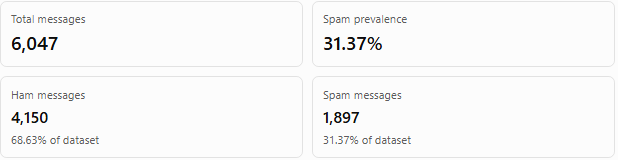

In [ ]:
# our checks established unique file paths, not necessarily unique email content.
# We have not yet checked for duplicate messages.

# Extract structured email features



In [ ]:

from pathlib import Path
from email import policy
from email.parser import BytesParser
import re
import pandas as pd

PROJECT_DIR = Path("/content/trust_safety_risk_analytics")
manifest_path = PROJECT_DIR / "data" / "metadata" / "message_manifest.csv"
FEATURE_DIR = PROJECT_DIR / "data" / "processed"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(manifest_path)

url_pattern = re.compile(r"https?://|www\.", re.IGNORECASE)
feature_rows = []
parse_errors = []

for row in manifest.itertuples(index=False):
    file_path = PROJECT_DIR / row.relative_path

    try:
        raw_bytes = file_path.read_bytes()
        msg = BytesParser(policy=policy.default).parsebytes(raw_bytes)

        # Collect text only in memory for feature calculation.
        # Never print or save raw message text.
        text_parts = []
        has_plain_text = False
        has_html = False
        attachment_count = 0
        mime_part_count = 0

        for part in msg.walk():
            mime_part_count += 1
            content_type = part.get_content_type()
            disposition = part.get_content_disposition()

            if disposition == "attachment":
                attachment_count += 1
                continue

            if part.is_multipart():
                continue

            if content_type == "text/plain":
                has_plain_text = True
            elif content_type == "text/html":
                has_html = True
            else:
                continue

            try:
                content = part.get_content()
                if isinstance(content, str):
                    text_parts.append(content)
            except Exception:
                # Keep processing other parts if one part fails decoding.
                continue

        body = "\n".join(text_parts)
        subject = str(msg.get("Subject", "") or "")
        uppercase_letters = sum(ch.isupper() for ch in body)
        alphabetic_letters = sum(ch.isalpha() for ch in body)

        feature_rows.append({
            "message_id": row.message_id,
            "source_folder": row.source_folder,
            "label": row.label,
            "message_bytes": len(raw_bytes),
            "header_count": len(msg.keys()),
            "has_subject": int(bool(subject.strip())),
            "subject_length": len(subject),
            "has_from": int(bool(msg.get("From"))),
            "has_reply_to": int(bool(msg.get("Reply-To"))),
            "has_return_path": int(bool(msg.get("Return-Path"))),
            "has_message_id_header": int(bool(msg.get("Message-ID"))),
            "received_header_count": len(msg.get_all("Received", [])),
            "is_multipart": int(msg.is_multipart()),
            "mime_part_count": mime_part_count,
            "has_plain_text_part": int(has_plain_text),
            "has_html_part": int(has_html),
            "attachment_count": attachment_count,
            "body_chars": len(body),
            "url_count": len(url_pattern.findall(body)),
            "exclamation_count": body.count("!"),
            "uppercase_ratio": (
                uppercase_letters / alphabetic_letters
                if alphabetic_letters else 0.0
            ),
        })

    except Exception as exc:
        # Record the file identifier and error type, not message content.
        parse_errors.append({
            "message_id": row.message_id,
            "error_type": type(exc).__name__,
        })

features = pd.DataFrame(feature_rows)

output_path = FEATURE_DIR / "structured_features.csv"
errors_path = FEATURE_DIR / "parse_errors.csv"

features.to_csv(output_path, index=False)
pd.DataFrame(
    parse_errors, columns=["message_id", "error_type"]
).to_csv(errors_path, index=False)

print("PARSING SUMMARY")
print("Messages in manifest:", len(manifest))
print("Successfully parsed:", len(features))
print("Parse errors:", len(parse_errors))
print("Feature columns:", len(features.columns))

print("\nLABEL COUNTS IN EXTRACTED TABLE")
display(features["label"].value_counts().rename_axis("label").reset_index(name="count"))

print("\nMISSING VALUES IN FEATURE TABLE")
display(
    features.isna().sum()
    .rename("missing_count")
    .reset_index()
    .rename(columns={"index": "feature"})
    .query("missing_count > 0")
)

print("\nSAMPLE FEATURE ROWS — no raw email content")
display(features.head(5))

print("\nSaved feature table:", output_path)
print("Saved parsing error log:", errors_path)


PARSING SUMMARY
Messages in manifest: 6047
Successfully parsed: 6047
Parse errors: 0
Feature columns: 21

LABEL COUNTS IN EXTRACTED TABLE


,label,count
0,ham,4150
1,spam,1897



MISSING VALUES IN FEATURE TABLE


,feature,missing_count



SAMPLE FEATURE ROWS — no raw email content


,message_id,source_folder,label,message_bytes,header_count,has_subject,subject_length,has_from,has_reply_to,has_return_path,...,received_header_count,is_multipart,mime_part_count,has_plain_text_part,has_html_part,attachment_count,body_chars,url_count,exclamation_count,uppercase_ratio
0,01612.cdcef456e3de75e0c6478cee11565c41,easy_ham,ham,3644,33,1,38,1,1,1,...,6,0,1,1,0,0,826,2,0,0.232108
1,01394.cdeefbed999cb93e1643908d2c30f217,easy_ham,ham,1748,18,1,40,1,0,1,...,5,0,1,1,0,0,144,0,0,0.119565
2,01858.c6147940a2048fd84b1d8c2d0485a9b6,easy_ham,ham,1510,11,1,78,1,0,1,...,3,0,1,1,0,0,557,3,0,0.067708
3,00456.6932df857bc1b0c8766e5a9794d167ba,easy_ham,ham,4372,31,1,11,1,0,1,...,8,0,1,1,0,0,2096,2,1,0.032300
4,00671.daf16d838d9b71f5f6cf09d54ebc1e3c,easy_ham,ham,3379,35,1,62,1,1,1,...,8,0,1,1,0,0,909,3,0,0.048120



Saved feature table: /content/trust_safety_risk_analytics/data/processed/structured_features.csv
Saved parsing error log: /content/trust_safety_risk_analytics/data/processed/parse_errors.csv


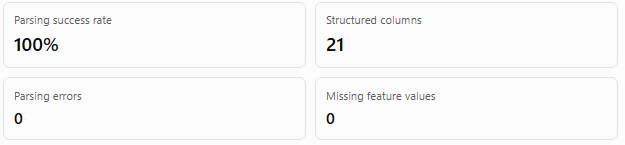

 Before building a model, we need to answer three questions:
1. Do any messages contain identical raw content?
2. Are any candidate features constant, invalid, or suspiciously associated with the dataset's source folders?
3. Do the structured features show differences between spam and ham that are worth investigating?


In [ ]:

from pathlib import Path
import hashlib
import numpy as np
import pandas as pd

PROJECT_DIR = Path("/content/trust_safety_risk_analytics")
FEATURE_PATH = PROJECT_DIR / "data" / "processed" / "structured_features.csv"
MANIFEST_PATH = PROJECT_DIR / "data" / "metadata" / "message_manifest.csv"
EXTRACT_DIR = PROJECT_DIR / "data" / "raw" / "extracted"
REPORT_DIR = PROJECT_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(FEATURE_PATH)
manifest = pd.read_csv(MANIFEST_PATH)

# 1. Validate expected structure and labels
assert len(df) == 6047, f"Unexpected row count: {len(df)}"
assert df["message_id"].is_unique, "Duplicate message IDs found"
assert set(df["label"].unique()) == {"ham", "spam"}

# These are identifiers/provenance, not legitimate model predictors.
excluded_columns = ["message_id", "source_folder", "label"]
candidate_features = [
    c for c in df.columns if c not in excluded_columns
]

# 2. Check candidate feature data types, missing values and constants
numeric_df = df[candidate_features].select_dtypes(include=[np.number])

feature_quality = pd.DataFrame({
    "feature": candidate_features,
    "dtype": [str(df[c].dtype) for c in candidate_features],
    "missing_count": [int(df[c].isna().sum()) for c in candidate_features],
    "unique_values": [int(df[c].nunique(dropna=False)) for c in candidate_features],
    "constant_feature": [df[c].nunique(dropna=False) <= 1 for c in candidate_features],
})

nonfinite_counts = {}
for col in numeric_df.columns:
    values = pd.to_numeric(numeric_df[col], errors="coerce")
    nonfinite_counts[col] = int((~np.isfinite(values)).sum())

feature_quality["nonfinite_count"] = (
    feature_quality["feature"].map(nonfinite_counts).fillna(0).astype(int)
)

# 3. Check exact raw-message duplicates using SHA-256.
# Only hashes and counts are retained; raw messages are not displayed or saved.
hash_records = []

for row in manifest.itertuples(index=False):
    path = PROJECT_DIR / row.relative_path
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    hash_records.append({
        "message_id": row.message_id,
        "source_folder": row.source_folder,
        "label": row.label,
        "sha256": digest
    })

hash_df = pd.DataFrame(hash_records)
duplicate_hash_rows = hash_df[hash_df.duplicated("sha256", keep=False)].copy()

# 4. Inspect how source folders map to labels.
source_label_counts = pd.crosstab(
    df["source_folder"], df["label"], margins=True
).reset_index()

# 5. Compare feature distributions by label using medians.
# Medians are descriptive, not proof that a feature is predictive.
distribution_rows = []

for col in numeric_df.columns:
    ham_values = pd.to_numeric(df.loc[df["label"] == "ham", col], errors="coerce")
    spam_values = pd.to_numeric(df.loc[df["label"] == "spam", col], errors="coerce")

    distribution_rows.append({
        "feature": col,
        "ham_median": ham_values.median(),
        "spam_median": spam_values.median(),
        "ham_mean": ham_values.mean(),
        "spam_mean": spam_values.mean(),
    })

feature_by_label = pd.DataFrame(distribution_rows)

# Save audit outputs
feature_quality.to_csv(REPORT_DIR / "feature_quality_audit.csv", index=False)
source_label_counts.to_csv(REPORT_DIR / "source_folder_label_audit.csv", index=False)
feature_by_label.to_csv(REPORT_DIR / "feature_distributions_by_label.csv", index=False)
duplicate_hash_rows.to_csv(REPORT_DIR / "duplicate_message_hashes.csv", index=False)

print("AUDIT SUMMARY")
print("Rows:", len(df))
print("Candidate model features:", len(candidate_features))
print("Constant candidate features:",
      int(feature_quality["constant_feature"].sum()))
print("Features with missing values:",
      int((feature_quality["missing_count"] > 0).sum()))
print("Features with non-finite numeric values:",
      int((feature_quality["nonfinite_count"] > 0).sum()))
print("Messages participating in exact-content duplicate groups:",
      len(duplicate_hash_rows))
print("Unique raw-message hashes:", hash_df["sha256"].nunique())

print("\nFEATURE QUALITY")
display(feature_quality)

print("\nSOURCE FOLDER TO LABEL MAPPING")
display(source_label_counts)

print("\nFEATURE DISTRIBUTIONS BY LABEL")
display(feature_by_label.round(3))

print("\nAudit reports saved in:", REPORT_DIR)


AUDIT SUMMARY
Rows: 6047
Candidate model features: 18
Constant candidate features: 0
Features with missing values: 0
Features with non-finite numeric values: 0
Messages participating in exact-content duplicate groups: 0
Unique raw-message hashes: 6047

FEATURE QUALITY


,feature,dtype,missing_count,unique_values,constant_feature,nonfinite_count
0,message_bytes,int64,0,4018,False,0
1,header_count,int64,0,51,False,0
2,has_subject,int64,0,2,False,0
3,subject_length,int64,0,125,False,0
4,has_from,int64,0,2,False,0
5,has_reply_to,int64,0,2,False,0
6,has_return_path,int64,0,2,False,0
7,has_message_id_header,int64,0,2,False,0
8,received_header_count,int64,0,16,False,0
9,is_multipart,int64,0,2,False,0



SOURCE FOLDER TO LABEL MAPPING


label,source_folder,ham,spam,All
0,easy_ham,2500,0,2500
1,easy_ham_2,1400,0,1400
2,hard_ham,250,0,250
3,spam,0,500,500
4,spam_2,0,1397,1397
5,All,4150,1897,6047



FEATURE DISTRIBUTIONS BY LABEL


,feature,ham_median,spam_median,ham_mean,spam_mean
0,message_bytes,3389.000,4082.000,4849.647,6527.383
1,header_count,30.000,17.000,26.280,18.505
2,has_subject,1.000,1.000,0.999,0.993
3,subject_length,34.000,37.000,37.175,39.638
4,has_from,1.000,1.000,1.000,0.999
5,has_reply_to,0.000,0.000,0.284,0.452
6,has_return_path,1.000,1.000,0.998,0.889
7,has_message_id_header,1.000,1.000,1.000,0.999
8,received_header_count,6.000,4.000,5.846,4.389
9,is_multipart,0.000,0.000,0.048,0.161



Audit reports saved in: /content/trust_safety_risk_analytics/reports


The audit looks good on basic integrity:
- 6,047 messages and 18 candidate numeric features.
- No constant features, missing values, or non-finite numeric values.
- No exact duplicate raw messages detected by SHA-256.
- Every source folder maps exclusively to one label.

The last point is the key risk. Because source_folder perfectly identifies ham versus spam, we must never use it as a model input. We will also exclude message_id and any derived file-path information.

For this project, We will do source-folder holdout split: keep entire source folders out of training and use them only for testing. This is a more meaningful generalization check for our available dataset, although it cannot eliminate every form of dataset bias.

We will use:

- Training: easy_ham, hard_ham, spam_2
- Testing: easy_ham_2, spam

This gives both sets examples of ham and spam while ensuring no source folder appears in both. The split is deliberately not a conventional random 80/20 split.

In [ ]:
# Create a source-aware train/test split


from pathlib import Path
import pandas as pd

PROJECT_DIR = Path("/content/trust_safety_risk_analytics")
FEATURE_PATH = PROJECT_DIR / "data" / "processed" / "structured_features.csv"
REPORT_DIR = PROJECT_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(FEATURE_PATH)

TRAIN_FOLDERS = {"easy_ham", "hard_ham", "spam_2"}
TEST_FOLDERS = {"easy_ham_2", "spam"}

assert TRAIN_FOLDERS.isdisjoint(TEST_FOLDERS)
assert set(df["source_folder"].unique()) == TRAIN_FOLDERS | TEST_FOLDERS

df["split"] = df["source_folder"].map(
    lambda folder: "train" if folder in TRAIN_FOLDERS else "test"
)

assert df["split"].notna().all()
assert df.groupby("source_folder")["split"].nunique().max() == 1

train_df = df[df["split"] == "train"].copy()
test_df = df[df["split"] == "test"].copy()

assert set(train_df["label"]) == {"ham", "spam"}
assert set(test_df["label"]) == {"ham", "spam"}
assert set(train_df["source_folder"]).isdisjoint(
    set(test_df["source_folder"])
)
assert len(train_df) + len(test_df) == len(df)

# Save the split assignment separately for reproducibility.
split_manifest = df[
    ["message_id", "source_folder", "label", "split"]
].copy()

split_path = PROJECT_DIR / "data" / "metadata" / "split_manifest.csv"
split_manifest.to_csv(split_path, index=False)

print("SPLIT VALIDATION PASSED")
print("Training rows:", len(train_df))
print("Test rows:", len(test_df))
print("Training folders:", sorted(train_df["source_folder"].unique()))
print("Test folders:", sorted(test_df["source_folder"].unique()))

print("\nLABEL DISTRIBUTION BY SPLIT")
split_summary = (
    df.groupby(["split", "label"])
    .size()
    .rename("count")
    .reset_index()
)
split_summary["percentage_within_split"] = (
    split_summary["count"]
    / split_summary["split"].map(df["split"].value_counts())
    * 100
).round(2)
display(split_summary)

print("\nSOURCE FOLDER DISTRIBUTION")
display(
    pd.crosstab(df["source_folder"], df["split"])
    .reset_index()
)

print("\nSplit manifest saved to:", split_path)


SPLIT VALIDATION PASSED
Training rows: 4147
Test rows: 1900
Training folders: ['easy_ham', 'hard_ham', 'spam_2']
Test folders: ['easy_ham_2', 'spam']

LABEL DISTRIBUTION BY SPLIT


,split,label,count,percentage_within_split
0,test,ham,1400,73.68
1,test,spam,500,26.32
2,train,ham,2750,66.31
3,train,spam,1397,33.69



SOURCE FOLDER DISTRIBUTION


split,source_folder,test,train
0,easy_ham,0,2500
1,easy_ham_2,1400,0
2,hard_ham,0,250
3,spam,500,0
4,spam_2,0,1397



Split manifest saved to: /content/trust_safety_risk_analytics/data/metadata/split_manifest.csv


In [ ]:
# Establish a baseline before machine learning

## majority-class baseline: a model that always predicts ham,
##regardless of the message's features.


from pathlib import Path
import pandas as pd

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

PROJECT_DIR = Path("/content/trust_safety_risk_analytics")
FEATURE_PATH = PROJECT_DIR / "data" / "processed" / "structured_features.csv"
SPLIT_PATH = PROJECT_DIR / "data" / "metadata" / "split_manifest.csv"
REPORT_DIR = PROJECT_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

features_df = pd.read_csv(FEATURE_PATH)
split_df = pd.read_csv(SPLIT_PATH)

df = features_df.merge(
    split_df[["message_id", "split"]],
    on="message_id",
    how="inner",
    validate="one_to_one"
)

assert len(df) == len(features_df), "Some feature rows did not match the split manifest"

# Exclude identifiers, provenance, target and split metadata.
excluded_columns = {
    "message_id", "source_folder", "label", "split"
}
feature_columns = [
    col for col in df.columns if col not in excluded_columns
]

X_train = df.loc[df["split"] == "train", feature_columns]
y_train = (df.loc[df["split"] == "train", "label"] == "spam").astype(int)

X_test = df.loc[df["split"] == "test", feature_columns]
y_test = (df.loc[df["split"] == "test", "label"] == "spam").astype(int)

assert list(X_train.columns) == list(X_test.columns)
assert "source_folder" not in X_train.columns
assert "message_id" not in X_train.columns
assert len(X_train) == 4147
assert len(X_test) == 1900

# Baseline: always predict the most common training class.
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
y_pred = baseline.predict(X_test)

baseline_metrics = {
    "model": "Majority-class baseline",
    "accuracy": accuracy_score(y_test, y_pred),
    "spam_precision": precision_score(y_test, y_pred, zero_division=0),
    "spam_recall": recall_score(y_test, y_pred, zero_division=0),
    "spam_f1": f1_score(y_test, y_pred, zero_division=0),
}

metrics_df = pd.DataFrame([baseline_metrics])

print("FEATURE VALIDATION")
print("Model input features:", len(feature_columns))
print("Features:", feature_columns)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

print("\nBASELINE METRICS")
display(metrics_df.round(4))

print("\nCONFUSION MATRIX")
print("Label order: [ham (0), spam (1)]")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["ham", "spam"],
    zero_division=0
))

metrics_df.to_csv(
    REPORT_DIR / "baseline_metrics.csv",
    index=False
)
print("\nBaseline report saved to:", REPORT_DIR / "baseline_metrics.csv")


FEATURE VALIDATION
Model input features: 18
Features: ['message_bytes', 'header_count', 'has_subject', 'subject_length', 'has_from', 'has_reply_to', 'has_return_path', 'has_message_id_header', 'received_header_count', 'is_multipart', 'mime_part_count', 'has_plain_text_part', 'has_html_part', 'attachment_count', 'body_chars', 'url_count', 'exclamation_count', 'uppercase_ratio']
Training rows: 4147
Test rows: 1900

BASELINE METRICS


,model,accuracy,spam_precision,spam_recall,spam_f1
0,Majority-class baseline,0.7368,0.0,0.0,0.0



CONFUSION MATRIX
Label order: [ham (0), spam (1)]
[[1400    0]
 [ 500    0]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

         ham       0.74      1.00      0.85      1400
        spam       0.00      0.00      0.00       500

    accuracy                           0.74      1900
   macro avg       0.37      0.50      0.42      1900
weighted avg       0.54      0.74      0.63      1900


Baseline report saved to: /content/trust_safety_risk_analytics/reports/baseline_metrics.csv


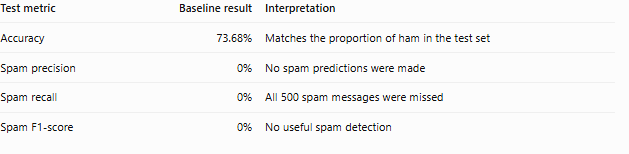

In [ ]:


from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

PROJECT_DIR = Path("/content/trust_safety_risk_analytics")
FEATURE_PATH = PROJECT_DIR / "data" / "processed" / "structured_features.csv"
SPLIT_PATH = PROJECT_DIR / "data" / "metadata" / "split_manifest.csv"
REPORT_DIR = PROJECT_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

features_df = pd.read_csv(FEATURE_PATH)
split_df = pd.read_csv(SPLIT_PATH)

df = features_df.merge(
    split_df[["message_id", "split"]],
    on="message_id",
    how="inner",
    validate="one_to_one"
)

excluded_columns = {"message_id", "source_folder", "label", "split"}
feature_columns = [
    col for col in df.columns if col not in excluded_columns
]

train_df = df[df["split"] == "train"].copy()
test_df = df[df["split"] == "test"].copy()

X_train = train_df[feature_columns]
y_train = (train_df["label"] == "spam").astype(int)

X_test = test_df[feature_columns]
y_test = (test_df["label"] == "spam").astype(int)

# Scaling is fitted only on the training data.
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])

logistic_model.fit(X_train, y_train)

# Use the default probability threshold for this first evaluation.
spam_probabilities = logistic_model.predict_proba(X_test)[:, 1]
y_pred = (spam_probabilities >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred, labels=[0, 1]
).ravel()

metrics = {
    "model": "Logistic Regression",
    "threshold": 0.5,
    "accuracy": accuracy_score(y_test, y_pred),
    "spam_precision": precision_score(y_test, y_pred, zero_division=0),
    "spam_recall": recall_score(y_test, y_pred, zero_division=0),
    "spam_f1": f1_score(y_test, y_pred, zero_division=0),
    "false_positive_rate": fp / (fp + tn) if (fp + tn) else 0,
    "false_negative_rate": fn / (fn + tp) if (fn + tp) else 0,
    "roc_auc": roc_auc_score(y_test, spam_probabilities),
    "average_precision": average_precision_score(y_test, spam_probabilities),
    "true_negatives": int(tn),
    "false_positives": int(fp),
    "false_negatives": int(fn),
    "true_positives": int(tp)
}

metrics_df = pd.DataFrame([metrics])

print("LOGISTIC REGRESSION — TEST RESULTS")
display(metrics_df.round(4))

print("\nCONFUSION MATRIX")
print("Label order: [ham (0), spam (1)]")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

print("\nCOMPARISON WITH BASELINE")
baseline_path = REPORT_DIR / "baseline_metrics.csv"
baseline_df = pd.read_csv(baseline_path)

comparison = pd.DataFrame([
    {
        "model": "Majority-class baseline",
        "accuracy": baseline_df.loc[0, "accuracy"],
        "spam_precision": baseline_df.loc[0, "spam_precision"],
        "spam_recall": baseline_df.loc[0, "spam_recall"],
        "spam_f1": baseline_df.loc[0, "spam_f1"]
    },
    {
        "model": "Logistic Regression",
        "accuracy": metrics["accuracy"],
        "spam_precision": metrics["spam_precision"],
        "spam_recall": metrics["spam_recall"],
        "spam_f1": metrics["spam_f1"]
    }
])
display(comparison.round(4))

metrics_df.to_csv(
    REPORT_DIR / "logistic_regression_metrics.csv",
    index=False
)

print("\nSaved metrics to:",
      REPORT_DIR / "logistic_regression_metrics.csv")


LOGISTIC REGRESSION — TEST RESULTS


,model,threshold,accuracy,spam_precision,spam_recall,spam_f1,false_positive_rate,false_negative_rate,roc_auc,average_precision,true_negatives,false_positives,false_negatives,true_positives
0,Logistic Regression,0.5,0.8874,0.9333,0.616,0.7422,0.0157,0.384,0.9401,0.9041,1378,22,192,308



CONFUSION MATRIX
Label order: [ham (0), spam (1)]
[[1378   22]
 [ 192  308]]

COMPARISON WITH BASELINE


,model,accuracy,spam_precision,spam_recall,spam_f1
0,Majority-class baseline,0.7368,0.0000,0.000,0.0000
1,Logistic Regression,0.8874,0.9333,0.616,0.7422



Saved metrics to: /content/trust_safety_risk_analytics/reports/logistic_regression_metrics.csv


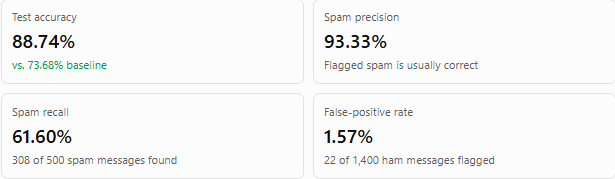

The model's ROC-AUC of 0.9401 indicates strong ranking performance on this held-out source-group test set. Average precision is 0.9041. Neither metric guarantees performance on modern email traffic, and the source-aware split remains a historical-corpus evaluation.

In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

PROJECT_DIR = Path("/content/trust_safety_risk_analytics")
FEATURE_PATH = PROJECT_DIR / "data" / "processed" / "structured_features.csv"
SPLIT_PATH = PROJECT_DIR / "data" / "metadata" / "split_manifest.csv"
REPORT_DIR = PROJECT_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

features_df = pd.read_csv(FEATURE_PATH)
split_df = pd.read_csv(SPLIT_PATH)

df = features_df.merge(
    split_df[["message_id", "split"]],
    on="message_id",
    how="inner",
    validate="one_to_one"
)

train_df = df[df["split"] == "train"].copy()

excluded_columns = {"message_id", "source_folder", "label", "split"}
feature_columns = [c for c in df.columns if c not in excluded_columns]

X = train_df[feature_columns]
y = (train_df["label"] == "spam").astype(int)

# Validation is drawn only from the training partition.
X_subtrain, X_valid, y_subtrain, y_valid = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

validation_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])

validation_model.fit(X_subtrain, y_subtrain)
valid_probabilities = validation_model.predict_proba(X_valid)[:, 1]

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]
rows = []

for threshold in thresholds:
    pred = (valid_probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_valid, pred, labels=[0, 1]
    ).ravel()

    rows.append({
        "threshold": threshold,
        "precision": precision_score(y_valid, pred, zero_division=0),
        "recall": recall_score(y_valid, pred, zero_division=0),
        "f1": f1_score(y_valid, pred, zero_division=0),
        "false_positive_rate": fp / (fp + tn) if (fp + tn) else 0,
        "ham_flagged": int(fp),
        "spam_detected": int(tp),
        "spam_missed": int(fn),
        "total_flagged_for_review": int(tp + fp),
        "review_rate": (tp + fp) / len(y_valid)
    })

threshold_df = pd.DataFrame(rows)

threshold_path = REPORT_DIR / "threshold_validation_results.csv"
threshold_df.to_csv(threshold_path, index=False)

print("INTERNAL VALIDATION SPLIT")
print("Subtraining rows:", len(X_subtrain))
print("Validation rows:", len(X_valid))
print("Validation spam prevalence:", round(y_valid.mean() * 100, 2), "%")

print("\nTHRESHOLD COMPARISON")
display(threshold_df.round(4))

print("\nSaved to:", threshold_path)


INTERNAL VALIDATION SPLIT
Subtraining rows: 3317
Validation rows: 830
Validation spam prevalence: 33.73 %

THRESHOLD COMPARISON


,threshold,precision,recall,f1,false_positive_rate,ham_flagged,spam_detected,spam_missed,total_flagged_for_review,review_rate
0,0.2,0.7246,0.8929,0.8000,0.1727,95,250,30,345,0.4157
1,0.3,0.8467,0.8286,0.8375,0.0764,42,232,48,274,0.3301
2,0.4,0.9215,0.7964,0.8544,0.0345,19,223,57,242,0.2916
3,0.5,0.9356,0.7786,0.8499,0.0273,15,218,62,233,0.2807
4,0.6,0.9420,0.7536,0.8373,0.0236,13,211,69,224,0.2699
5,0.7,0.9474,0.7071,0.8098,0.0200,11,198,82,209,0.2518
6,0.8,0.9524,0.6429,0.7676,0.0164,9,180,100,189,0.2277



Saved to: /content/trust_safety_risk_analytics/reports/threshold_validation_results.csv


At threshold 0.40, on the validation set:
- 223 spam messages detected out of 280.
- 57 spam messages missed.
- 19 legitimate messages incorrectly flagged.
- 242 messages flagged for review, approximately 29.16% of the validation set.
- F1 score: 0.8544, the highest among the tested thresholds.

In [ ]:

# Step 8: Final model evaluation at the selected threshold

import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix
)

BASE = "/content/trust_safety_risk_analytics"
THRESHOLD = 0.40

features = pd.read_csv(
    f"{BASE}/data/processed/structured_features.csv"
)
split_manifest = pd.read_csv(
    f"{BASE}/data/metadata/split_manifest.csv"
)

data = features.merge(
    split_manifest[["message_id", "split"]],
    on="message_id",
    how="inner",
    validate="one_to_one"
)

# Exclude identifiers, source metadata, and target from predictors.
excluded = {"message_id", "source_folder", "label", "split"}
X = data.drop(columns=list(excluded))
y = data["label"].map({"ham": 0, "spam": 1})

train_mask = data["split"].eq("train")
test_mask = data["split"].eq("test")

X_train, y_train = X.loc[train_mask], y.loc[train_mask]
X_test, y_test = X.loc[test_mask], y.loc[test_mask]

# Fit preprocessing and model using training data only.
final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

final_model.fit(X_train, y_train)

# Evaluate on the untouched held-out test set.
spam_probability = final_model.predict_proba(X_test)[:, 1]
y_pred = (spam_probability >= THRESHOLD).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred, labels=[0, 1]
).ravel()

results = pd.DataFrame([{
    "threshold": THRESHOLD,
    "test_messages": len(y_test),
    "accuracy": accuracy_score(y_test, y_pred),
    "spam_precision": precision_score(
        y_test, y_pred, zero_division=0
    ),
    "spam_recall": recall_score(
        y_test, y_pred, zero_division=0
    ),
    "spam_f1": f1_score(
        y_test, y_pred, zero_division=0
    ),
    "false_positive_rate": fp / (fp + tn),
    "roc_auc": roc_auc_score(y_test, spam_probability),
    "average_precision": average_precision_score(
        y_test, spam_probability
    ),
    "true_negatives": tn,
    "false_positives": fp,
    "false_negatives": fn,
    "true_positives": tp,
    "total_flagged_for_review": fp + tp,
    "review_rate": (fp + tp) / len(y_test)
}])

output_path = f"{BASE}/reports/final_test_metrics.csv"
results.to_csv(output_path, index=False)

display(results.round(4))
print(f"Saved to: {output_path}")


,threshold,test_messages,accuracy,spam_precision,spam_recall,spam_f1,false_positive_rate,roc_auc,average_precision,true_negatives,false_positives,false_negatives,true_positives,total_flagged_for_review,review_rate
0,0.4,1900,0.9016,0.9335,0.674,0.7828,0.0171,0.9401,0.9041,1376,24,163,337,361,0.19


Saved to: /content/trust_safety_risk_analytics/reports/final_test_metrics.csv


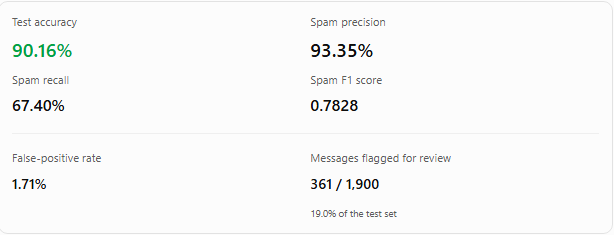

In [ ]:

# Step 9: Interpret Logistic Regression coefficients

classifier = final_model.named_steps["classifier"]

coefficient_table = pd.DataFrame({
    "feature": X_train.columns,
    "coefficient": classifier.coef_[0]
})

coefficient_table["direction"] = coefficient_table[
    "coefficient"
].apply(
    lambda value: "Higher spam risk" if value > 0
    else "Lower spam risk"
)

coefficient_table["absolute_coefficient"] = (
    coefficient_table["coefficient"].abs()
)

coefficient_table = coefficient_table.sort_values(
    "absolute_coefficient",
    ascending=False
).reset_index(drop=True)

# Display the strongest associations in both directions.
print("FEATURES MOST STRONGLY ASSOCIATED WITH SPAM RISK")
display(
    coefficient_table.head(10)[
        ["feature", "coefficient", "direction"]
    ].round(4)
)

print("FEATURES ASSOCIATED WITH LOWER SPAM RISK")
display(
    coefficient_table.sort_values(
        "coefficient", ascending=True
    ).head(10)[
        ["feature", "coefficient", "direction"]
    ].round(4)
)

output_path = (
    "/content/trust_safety_risk_analytics/reports/"
    "logistic_regression_feature_coefficients.csv"
)

coefficient_table.to_csv(output_path, index=False)
print(f"Saved to: {output_path}")


FEATURES MOST STRONGLY ASSOCIATED WITH SPAM RISK


,feature,coefficient,direction
0,url_count,-4.1736,Lower spam risk
1,exclamation_count,1.1152,Higher spam risk
2,has_html_part,1.1066,Higher spam risk
3,has_return_path,-0.8879,Lower spam risk
4,has_plain_text_part,-0.8457,Lower spam risk
5,uppercase_ratio,0.7408,Higher spam risk
6,is_multipart,0.5511,Higher spam risk
7,has_reply_to,0.5407,Higher spam risk
8,received_header_count,-0.4993,Lower spam risk
9,header_count,-0.4480,Lower spam risk


FEATURES ASSOCIATED WITH LOWER SPAM RISK


,feature,coefficient,direction
0,url_count,-4.1736,Lower spam risk
3,has_return_path,-0.8879,Lower spam risk
4,has_plain_text_part,-0.8457,Lower spam risk
8,received_header_count,-0.4993,Lower spam risk
9,header_count,-0.4480,Lower spam risk
10,mime_part_count,-0.3494,Lower spam risk
11,has_subject,-0.2008,Lower spam risk
12,has_message_id_header,-0.1181,Lower spam risk
13,has_from,-0.1123,Lower spam risk
14,body_chars,-0.0866,Lower spam risk


Saved to: /content/trust_safety_risk_analytics/reports/logistic_regression_feature_coefficients.csv


In [ ]:

# Step 10: Investigate URL counts and their relationship with labels

train_data = data.loc[data["split"].eq("train")].copy()

# Compare URL-count distributions by actual label.
url_summary = (
    train_data.groupby("label")["url_count"]
    .agg(
        message_count="count",
        mean="mean",
        median="median",
        zero_url_messages=lambda s: (s == 0).sum(),
        messages_with_urls=lambda s: (s > 0).sum(),
        maximum="max"
    )
    .reset_index()
)

url_summary["zero_url_rate"] = (
    url_summary["zero_url_messages"] / url_summary["message_count"]
)

url_summary["with_url_rate"] = (
    url_summary["messages_with_urls"] / url_summary["message_count"]
)

print("URL COUNT SUMMARY BY ACTUAL LABEL — TRAINING DATA")
display(url_summary.round(4))

# Compare spam prevalence for messages with and without URLs.
url_groups = (
    train_data.assign(
        url_group=train_data["url_count"].gt(0).map({
            True: "At least one URL",
            False: "No URLs"
        })
    )
    .groupby("url_group")
    .agg(
        messages=("label", "size"),
        spam_messages=("label", lambda s: (s == "spam").sum())
    )
    .reset_index()
)

url_groups["spam_rate"] = (
    url_groups["spam_messages"] / url_groups["messages"]
)

print("SPAM RATE BY URL PRESENCE — TRAINING DATA")
display(url_groups.round(4))

print(
    "Note: these are descriptive associations in the historical corpus, "
    "not evidence that URLs cause or prevent spam."
)


URL COUNT SUMMARY BY ACTUAL LABEL — TRAINING DATA


,label,message_count,mean,median,zero_url_messages,messages_with_urls,maximum,zero_url_rate,with_url_rate
0,ham,2750,15.5415,2.0,489,2261,4637,0.1778,0.8222
1,spam,1397,9.8733,3.0,245,1152,917,0.1754,0.8246


SPAM RATE BY URL PRESENCE — TRAINING DATA


,url_group,messages,spam_messages,spam_rate
0,At least one URL,3413,1152,0.3375
1,No URLs,734,245,0.3338


Note: these are descriptive associations in the historical corpus, not evidence that URLs cause or prevent spam.


In [ ]:

# Step 11: Sensitivity analysis — with vs. without url_count

from sklearn.base import clone

# Reuse the existing train/test split and selected threshold.
X_train_no_url = X_train.drop(columns=["url_count"])
X_test_no_url = X_test.drop(columns=["url_count"])

# Train a comparable pipeline without url_count.
model_without_url = clone(final_model)
model_without_url.fit(X_train_no_url, y_train)

prob_with_url = final_model.predict_proba(X_test)[:, 1]
prob_without_url = model_without_url.predict_proba(X_test_no_url)[:, 1]

def calculate_metrics(y_true, probabilities, threshold=0.40):
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    return {
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, predictions),
        "spam_precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "spam_recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "spam_f1": f1_score(
            y_true, predictions, zero_division=0
        ),
        "false_positive_rate": fp / (fp + tn),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "true_negatives": tn,
        "false_positives": fp,
        "false_negatives": fn,
        "true_positives": tp,
        "total_flagged_for_review": fp + tp
    }

sensitivity_results = pd.DataFrame([
    {
        "model": "All features",
        **calculate_metrics(y_test, prob_with_url)
    },
    {
        "model": "Without url_count",
        **calculate_metrics(y_test, prob_without_url)
    }
])

display(sensitivity_results.round(4))

sensitivity_path = (
    "/content/trust_safety_risk_analytics/reports/"
    "url_feature_sensitivity_check.csv"
)
sensitivity_results.to_csv(sensitivity_path, index=False)
print(f"Saved to: {sensitivity_path}")


,model,threshold,accuracy,spam_precision,spam_recall,spam_f1,false_positive_rate,roc_auc,true_negatives,false_positives,false_negatives,true_positives,total_flagged_for_review
0,All features,0.4,0.9016,0.9335,0.674,0.7828,0.0171,0.9401,1376,24,163,337,361
1,Without url_count,0.4,0.8916,0.9375,0.630,0.7536,0.0150,0.9187,1379,21,185,315,336


Saved to: /content/trust_safety_risk_analytics/reports/url_feature_sensitivity_check.csv


Sensitivity check shows that removing url_count reduces model performance on the held-out test set. The negative coefficient is counterintuitive, but the feature still appears useful to the model in combination with other variables.

In [ ]:
# Build the final project summary and model evaluation report


# Step 12A: Verify the key project artifacts

from pathlib import Path

BASE = Path("/content/trust_safety_risk_analytics")

required_files = [
    "data/metadata/message_manifest.csv",
    "data/metadata/split_manifest.csv",
    "data/processed/structured_features.csv",
    "reports/feature_quality_audit.csv",
    "reports/baseline_metrics.csv",
    "reports/logistic_regression_metrics.csv",
    "reports/threshold_validation_results.csv",
    "reports/final_test_metrics.csv",
    "reports/logistic_regression_feature_coefficients.csv",
    "reports/url_feature_sensitivity_check.csv"
]

artifact_check = pd.DataFrame([
    {
        "file": filename,
        "exists": (BASE / filename).is_file(),
        "size_kb": (
            round((BASE / filename).stat().st_size / 1024, 2)
            if (BASE / filename).is_file()
            else None
        )
    }
    for filename in required_files
])

display(artifact_check)

missing_files = artifact_check.loc[
    ~artifact_check["exists"], "file"
].tolist()

if missing_files:
    print("Missing artifacts:", missing_files)
else:
    print("All required artifacts are present.")


,file,exists,size_kb
0,data/metadata/message_manifest.csv,True,730.73
1,data/metadata/split_manifest.csv,True,340.59
2,data/processed/structured_features.csv,True,671.12
3,reports/feature_quality_audit.csv,True,0.67
4,reports/baseline_metrics.csv,True,0.10
5,reports/logistic_regression_metrics.csv,True,0.35
6,reports/threshold_validation_results.csv,True,0.88
7,reports/final_test_metrics.csv,True,0.36
8,reports/logistic_regression_feature_coefficien...,True,1.30
9,reports/url_feature_sensitivity_check.csv,True,0.42


All required artifacts are present.


In [ ]:

# Step 12B: Create the project report and GitHub README

report_dir = BASE / "reports"
report_dir.mkdir(parents=True, exist_ok=True)

final_metrics = pd.read_csv(report_dir / "final_test_metrics.csv").iloc[0]
threshold_metrics = pd.read_csv(
    report_dir / "threshold_validation_results.csv"
)
sensitivity = pd.read_csv(
    report_dir / "url_feature_sensitivity_check.csv"
)
quality_audit = pd.read_csv(
    report_dir / "feature_quality_audit.csv"
)

def pct(value):
    return f"{value:.2%}"

report = f"""# Trust & Safety Risk Operations Analytics

## 1. Executive summary

This project develops an interpretable machine-learning prototype for prioritizing
potentially unwanted email messages for risk review. It combines data-quality
controls, structured feature engineering, source-aware evaluation, Logistic
Regression, threshold selection, and operational workload analysis.

The project uses the historical Apache SpamAssassin Public Mail Corpus. It is an
independent portfolio project and is not affiliated with Google or based on
internal Google data.

At the selected classification threshold of {final_metrics['threshold']:.2f},
the model achieved {pct(final_metrics['accuracy'])} accuracy, {pct(final_metrics['spam_precision'])}
spam precision, and {pct(final_metrics['spam_recall'])} spam recall on the held-out
test set. It flagged {int(final_metrics['total_flagged_for_review'])} of
{int(final_metrics['test_messages'])} test messages for hypothetical review.

## 2. Business problem

Trust & Safety operations often need to identify potentially harmful or unwanted
activity while balancing detection coverage, false positives, and limited review
capacity. This project demonstrates a small-scale version of that analytical
problem using spam classification as a proxy use case.

The intended workflow is risk prioritization for human review—not automatic
blocking or a claim of production-ready abuse detection.

## 3. Dataset and scope

- Source: Apache SpamAssassin Public Mail Corpus.
- Historical data: principally from the early 2000s.
- Total messages: 6,047.
- Legitimate messages (ham): 4,150.
- Spam messages: 1,897.
- Input: locally extracted email messages.
- Target: corpus folder-derived label (`ham` or `spam`).

The corpus is historical and may not represent modern email threats, user
behaviour, or current production traffic. Raw messages are not intended for
publication with this repository.

## 4. Data preparation and quality

The workflow downloaded and extracted five corpus archives, generated checksums,
built a message manifest, parsed messages, and created a structured feature table.

The structured dataset contains 6,047 messages and 18 numeric predictive features,
along with message identifiers, source-folder metadata, and labels. Parsing errors
were recorded separately.

The quality checks found no missing values, constant features, non-finite feature
values, or exact duplicate raw messages based on SHA-256 hashes. Source-folder
metadata was excluded from model predictors because it mapped directly to labels
and could create target leakage. Message identifiers were also excluded.

## 5. Feature engineering

The numeric predictors describe message structure and simple content statistics,
including:

- Message size and body length.
- Header counts and presence of selected headers.
- MIME structure, HTML/plain-text parts, and attachment count.
- URL and exclamation-mark counts.
- Uppercase-character ratio.

These features avoid advanced NLP, transformer models, and deep learning, making
the pipeline relatively easy to explain and reproduce.

## 6. Evaluation design

The project used a source-aware split, holding out entire source folders rather
than randomly mixing messages from every folder.

- Training partition: 4,147 messages.
- Held-out test partition: 1,900 messages.
- No source folders were shared between the two partitions.

Threshold selection was performed using an internal validation subset of the
training partition. The selected threshold was then applied to the held-out test
set.

This design tests performance across the selected corpus folders, but it does
not guarantee generalization to a modern or independently collected email stream.
The source-folder composition and label distribution differ between partitions.

## 7. Baseline and model

A majority-class baseline predicted every test message as legitimate. It achieved
73.68% accuracy but detected no spam, illustrating why accuracy alone is
insufficient for an imbalanced classification problem.

The primary model is a scikit-learn pipeline comprising StandardScaler and
Logistic Regression. The scaler is fitted on training data, preventing the test
set from influencing preprocessing.

## 8. Threshold selection

The threshold was selected using validation data, considering precision, recall,
F1 score, false-positive rate, and the number of messages that would be flagged
for review.

A threshold of 0.40 was selected provisionally because it provided the highest
F1 score among the tested validation thresholds while maintaining high precision.
This is an operational choice for a review-oriented prototype, not a universal
optimum. Different error costs and review-capacity constraints could justify
another threshold.

## 9. Final held-out test results

| Metric | Result |
|---|---:|
| Classification threshold | {final_metrics['threshold']:.2f} |
| Test messages | {int(final_metrics['test_messages']):,} |
| Accuracy | {pct(final_metrics['accuracy'])} |
| Spam precision | {pct(final_metrics['spam_precision'])} |
| Spam recall | {pct(final_metrics['spam_recall'])} |
| Spam F1 score | {final_metrics['spam_f1']:.4f} |
| False-positive rate | {pct(final_metrics['false_positive_rate'])} |
| ROC AUC | {final_metrics['roc_auc']:.4f} |
| Average precision | {final_metrics['average_precision']:.4f} |
| True negatives | {int(final_metrics['true_negatives']):,} |
| False positives | {int(final_metrics['false_positives']):,} |
| False negatives | {int(final_metrics['false_negatives']):,} |
| True positives | {int(final_metrics['true_positives']):,} |
| Messages flagged for review | {int(final_metrics['total_flagged_for_review']):,} |
| Review rate | {pct(final_metrics['review_rate'])} |

### Operational interpretation

At the selected threshold, the model correctly flagged
{int(final_metrics['true_positives'])} spam messages and missed
{int(final_metrics['false_negatives'])}. It incorrectly flagged
{int(final_metrics['false_positives'])} legitimate messages.

These figures demonstrate the trade-off between spam detection and legitimate
message disruption. A real deployment would require a defined cost model,
capacity limits, monitoring, and human-review safeguards.

## 10. Model interpretation and sensitivity

The Logistic Regression coefficients identify associations between predictors
and model scores. Positive coefficients are associated with higher predicted
spam risk, while negative coefficients are associated with lower predicted risk,
conditional on the other predictors.

The `url_count` feature had a strong negative coefficient, despite similar spam
prevalence among messages with and without URLs in the training data. Removing
this feature reduced test ROC AUC from 0.9401 to 0.9187 and test spam recall
from 67.4% to 63.0%, while reducing false positives from 24 to 21.

The feature was retained in the current model because it contributed to predictive
performance in this diagnostic comparison. Its counterintuitive coefficient
requires further investigation. Correlated predictors and corpus-specific patterns
may contribute to the observed relationship.

This sensitivity analysis reused the held-out test set after its initial
evaluation, so it is exploratory rather than an independent confirmation of
performance. Further model selection should use validation or cross-validation
within training data, followed by evaluation on a fresh external dataset.

## 11. Limitations and responsible use

1. The dataset is historical and may not reflect contemporary spam or abuse.
2. This project is not a Google system and does not establish performance on
   Gmail or other live services.
3. The source-aware split is useful but is not a substitute for external
   validation on newer data.
4. Predictive associations are not causal explanations.
5. The chosen threshold is provisional and depends on operational priorities.
6. False positives can disrupt legitimate users; automatic enforcement would
   require additional safeguards and evaluation.
7. Raw email content should not be published as part of the portfolio.

## 12. Recommended next steps

- Validate on a newer, independently sourced dataset.
- Define an explicit review-capacity and error-cost policy.
- Evaluate threshold stability and calibration.
- Investigate feature correlations and unexpected coefficients using training
  data only.
- Track precision, recall, false positives, and distribution shifts over time.
- Add a concise dashboard showing model performance and review workload.

## 13. Reproducibility and artifacts

Key artifacts are stored in the project directory:

- `data/metadata/message_manifest.csv`
- `data/metadata/split_manifest.csv`
- `data/processed/structured_features.csv`
- `reports/feature_quality_audit.csv`
- `reports/baseline_metrics.csv`
- `reports/threshold_validation_results.csv`
- `reports/final_test_metrics.csv`
- `reports/logistic_regression_feature_coefficients.csv`
- `reports/url_feature_sensitivity_check.csv`

The raw corpus and extracted messages are intentionally excluded from the
recommended public repository. Publish the code, documentation, and appropriate
derived artifacts only after reviewing dataset terms and privacy considerations.
"""

readme = """# Trust & Safety Risk Operations Analytics

An interpretable machine-learning portfolio project exploring email spam-risk
prioritization, threshold selection, and review workload.

## Project highlights

- Historical Apache SpamAssassin public corpus: 6,047 messages.
- Structured message features engineered with Python and Pandas.
- Source-aware train/test split to reduce source-folder overlap.
- Majority-class baseline and Logistic Regression pipeline.
- Validation-based threshold selection and held-out test evaluation.
- Precision, recall, F1, ROC AUC, confusion matrix, and review-rate analysis.
- Coefficient interpretation and feature sensitivity analysis.

## Held-out test results

At a provisional threshold of 0.40:

- Accuracy: 90.16%
- Spam precision: 93.35%
- Spam recall: 67.40%
- Spam F1: 0.7828
- ROC AUC: 0.9401
- False-positive rate: 1.71%
- Messages flagged for hypothetical review: 361 of 1,900

See `reports/project_report.md` for the methodology, full metrics, limitations,
and recommendations. The values above describe this historical test set and
should not be interpreted as expected production performance.

## Technology

Python, Pandas, NumPy, scikit-learn, Logistic Regression, data-quality checks,
feature engineering, classification metrics, and threshold analysis.

## Responsible-use note

This is an independent portfolio prototype, not a Google product or an analysis
of internal Google data. It uses historical spam data and does not demonstrate
performance on modern Gmail traffic. Raw messages should not be published.
"""

report_path = report_dir / "project_report.md"
readme_path = BASE / "README.md"

report_path.write_text(report, encoding="utf-8")
readme_path.write_text(readme, encoding="utf-8")

print("Created project documentation:")
print(f"Report: {report_path}")
print(f"README: {readme_path}")
print(f"Report size: {report_path.stat().st_size:,} bytes")
print(f"README size: {readme_path.stat().st_size:,} bytes")

print("\nReport opening:")
print(report[:1200])


Created project documentation:
Report: /content/trust_safety_risk_analytics/reports/project_report.md
README: /content/trust_safety_risk_analytics/README.md
Report size: 8,448 bytes
README size: 1,563 bytes

Report opening:
# Trust & Safety Risk Operations Analytics

## 1. Executive summary

This project develops an interpretable machine-learning prototype for prioritizing
potentially unwanted email messages for risk review. It combines data-quality
controls, structured feature engineering, source-aware evaluation, Logistic
Regression, threshold selection, and operational workload analysis.

The project uses the historical Apache SpamAssassin Public Mail Corpus. It is an
independent portfolio project and is not affiliated with Google or based on
internal Google data.

At the selected classification threshold of 0.40,
the model achieved 90.16% accuracy, 93.35%
spam precision, and 67.40% spam recall on the held-out
test set. It flagged 361 of
1900 test messages for hypothetical review.



In [ ]:

# Step 13: Final consistency checks and portfolio packaging

import zipfile

BASE = Path("/content/trust_safety_risk_analytics")
PACKAGE_DIR = BASE / "portfolio_package"
PACKAGE_DIR.mkdir(parents=True, exist_ok=True)

# 1. Verify headline metrics against the saved final evaluation.
final_metrics = pd.read_csv(
    BASE / "reports/final_test_metrics.csv"
).iloc[0]

checks = {
    "Test messages": int(final_metrics["test_messages"]) == 1900,
    "Threshold": abs(final_metrics["threshold"] - 0.40) < 1e-9,
    "Accuracy": abs(final_metrics["accuracy"] - 0.9016) < 0.001,
    "Spam precision": abs(final_metrics["spam_precision"] - 0.9335) < 0.001,
    "Spam recall": abs(final_metrics["spam_recall"] - 0.6740) < 0.001,
    "Spam F1": abs(final_metrics["spam_f1"] - 0.7828) < 0.001,
    "ROC AUC": abs(final_metrics["roc_auc"] - 0.9401) < 0.001,
}

check_table = pd.DataFrame([
    {"check": name, "passed": passed}
    for name, passed in checks.items()
])

display(check_table)

if not all(checks.values()):
    raise ValueError(
        "A consistency check failed. Review the saved metrics before packaging."
    )

# 2. Select documentation and derived outputs for sharing.
# Raw archives and extracted email messages are intentionally excluded.
files_to_package = [
    "README.md",
    "reports/project_report.md",
    "data/processed/structured_features.csv",
    "data/metadata/split_manifest.csv",
    "reports/feature_quality_audit.csv",
    "reports/source_folder_label_audit.csv",
    "reports/feature_distributions_by_label.csv",
    "reports/baseline_metrics.csv",
    "reports/logistic_regression_metrics.csv",
    "reports/threshold_validation_results.csv",
    "reports/final_test_metrics.csv",
    "reports/logistic_regression_feature_coefficients.csv",
    "reports/url_feature_sensitivity_check.csv",
]

missing = [
    filename for filename in files_to_package
    if not (BASE / filename).is_file()
]

if missing:
    raise FileNotFoundError(f"Required package files are missing: {missing}")

zip_path = BASE / "trust_safety_risk_operations_analytics.zip"

with zipfile.ZipFile(
    zip_path, mode="w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for filename in files_to_package:
        archive.write(
            BASE / filename,
            arcname=f"trust_safety_risk_operations_analytics/{filename}"
        )

# 3. Verify the ZIP contents and confirm raw email files are absent.
with zipfile.ZipFile(zip_path, "r") as archive:
    packaged_names = archive.namelist()

print("\nConsistency checks passed:", all(checks.values()))
print("Files packaged:", len(packaged_names))
print("ZIP size (MB):", round(zip_path.stat().st_size / (1024 * 1024), 2))
print("Package location:", zip_path)
print("\nPackaged files:")
for filename in packaged_names:
    print("-", filename)

assert not any(
    "/data/raw/" in name for name in packaged_names
), "Raw data was unexpectedly included."


,check,passed
0,Test messages,True
1,Threshold,True
2,Accuracy,True
3,Spam precision,True
4,Spam recall,True
5,Spam F1,True
6,ROC AUC,True



Consistency checks passed: True
Files packaged: 13
ZIP size (MB): 0.4
Package location: /content/trust_safety_risk_analytics/trust_safety_risk_operations_analytics.zip

Packaged files:
- trust_safety_risk_operations_analytics/README.md
- trust_safety_risk_operations_analytics/reports/project_report.md
- trust_safety_risk_operations_analytics/data/processed/structured_features.csv
- trust_safety_risk_operations_analytics/data/metadata/split_manifest.csv
- trust_safety_risk_operations_analytics/reports/feature_quality_audit.csv
- trust_safety_risk_operations_analytics/reports/source_folder_label_audit.csv
- trust_safety_risk_operations_analytics/reports/feature_distributions_by_label.csv
- trust_safety_risk_operations_analytics/reports/baseline_metrics.csv
- trust_safety_risk_operations_analytics/reports/logistic_regression_metrics.csv
- trust_safety_risk_operations_analytics/reports/threshold_validation_results.csv
- trust_safety_risk_operations_analytics/reports/final_test_metrics.csv

In [ ]:

from google.colab import files

zip_path = "/content/trust_safety_risk_analytics/trust_safety_risk_operations_analytics.zip"
files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>